# 采样、量化与混叠

用确定的采样时刻对合成正弦波取样，比较量化步长和采样频率对结果的影响。

## 八个采样值的编号、时间和增益

样本数 N： 8
样本编号 n： [0 1 2 3 4 5 6 7]
采样时刻 t： [0.    0.125 0.25  0.375 0.5   0.625 0.75  0.875]
x[3]： -1.0
处理后的 y： [ 0.  4.  2. -2. -4.  0.  2.  0.]


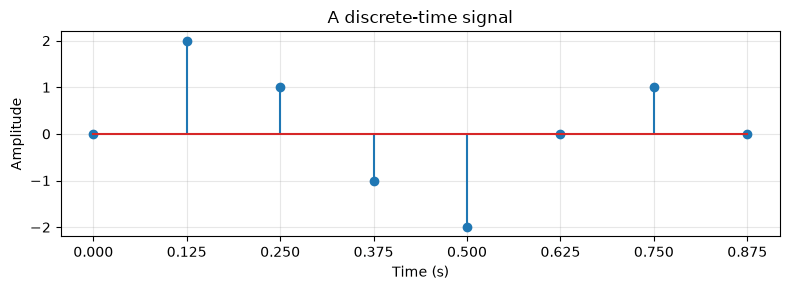

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 采样率：每秒 8 个样本
fs = 8

# 2. 一段人为指定的信号，共 8 个采样值
# 本例暂时不赋予具体物理单位
x = np.array([0.0, 2.0, 1.0, -1.0, -2.0, 0.0, 1.0, 0.0])

# 3. 样本总数
N = len(x)

# 4. 样本编号：0、1、2、...、N-1
n = np.arange(N)

# 5. 每个样本对应的时间，单位：秒
t = n / fs

# 6. 一个最简单的信号处理：所有采样值乘以 2
y = 2 * x

print("样本数 N：", N)
print("样本编号 n：", n)
print("采样时刻 t：", t)
print("x[3]：", x[3])
print("处理后的 y：", y)

# 7. 绘制离散采样点
plt.figure(figsize=(8, 3))
plt.stem(t, x)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("A discrete-time signal")

plt.xticks(t)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 两秒合成信号的频率、幅度与相位

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 采样设置
fs = 128             # 每秒采样 128 次
duration = 2.0       # 记录 2 秒
N = int(fs * duration)

# 每个采样点对应的时间，单位为秒
t = np.arange(N) / fs

# 信号设置：这里约定幅值单位为微伏
amplitude = 20.0
frequency = 10.0
phase = 0.0

# 在每一个采样时刻计算信号值
x = amplitude * np.sin(
    2 * np.pi * frequency * t + phase
)

print("采样点数：", N)
print("信号形状：", x.shape)
print("相邻采样点的间隔：", 1 / fs, "秒")
print("最后一个采样时刻：", t[-1], "秒")

采样点数： 256
信号形状： (256,)
相邻采样点的间隔： 0.0078125 秒
最后一个采样时刻： 1.9921875 秒


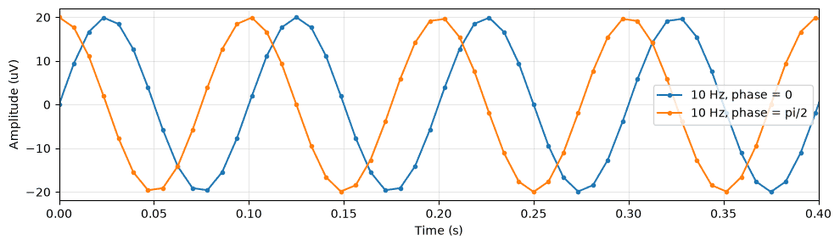

In [3]:
# 相同幅度、相同频率，初始相位改为 π/2
x_shift = amplitude * np.sin(
    2 * np.pi * frequency * t + np.pi / 2
)

plt.figure(figsize=(10, 3))

plt.plot(
    t, x,
    "o-", markersize=3,
    label="10 Hz, phase = 0"
)

plt.plot(
    t, x_shift,
    "o-", markersize=3,
    label="10 Hz, phase = pi/2"
)

# 只显示前 0.4 秒，便于观察
plt.xlim(0, 0.4)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude (uV)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 两条连续波可以有同一组采样值

采样值是否相同： True


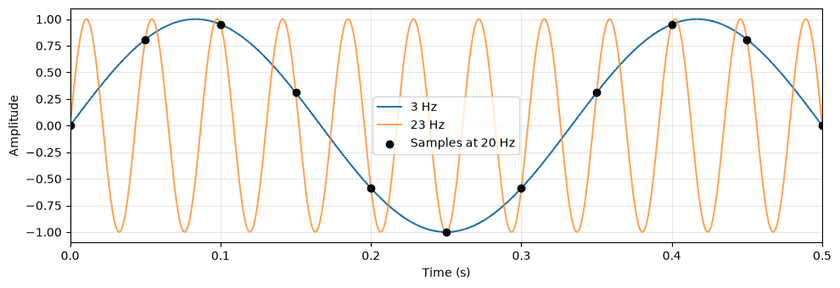

In [4]:
fs_demo = 20

# 1 秒内的 20 个采样时刻
t_sample = np.arange(fs_demo) / fs_demo

# 两条不同频率的波，在相同采样时刻的数值
low = np.sin(2 * np.pi * 3 * t_sample)
high = np.sin(2 * np.pi * 23 * t_sample)

print("采样值是否相同：", np.allclose(low, high))

# 使用更密集的时间点展示两条已知波形
t_dense = np.arange(2000) / 2000

plt.figure(figsize=(10, 3.5))

plt.plot(
    t_dense,
    np.sin(2 * np.pi * 3 * t_dense),
    label="3 Hz"
)

plt.plot(
    t_dense,
    np.sin(2 * np.pi * 23 * t_dense),
    label="23 Hz",
    alpha=0.7
)

# 两条波的采样值重合，只需画一组黑点
plt.scatter(
    t_sample, low,
    color="black",
    zorder=3,
    label="Samples at 20 Hz"
)

plt.xlim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 把 2 Hz 正弦波以 20 Hz 采样，再量化

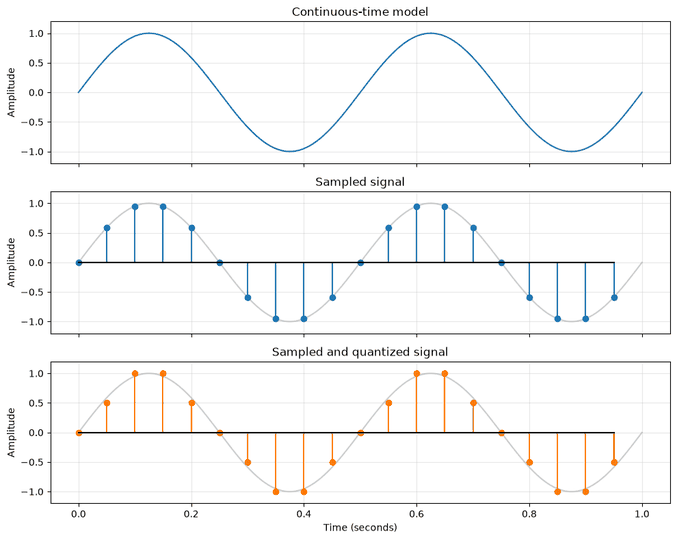

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 设置信号与采样参数
f0 = 2.0          # 信号频率：2 Hz
fs = 20          # 采样率：每秒 20 个样本
duration = 1.0   # 观察 1 秒

# 2. 用很多点画出一条平滑的参考曲线
# 这只是为了显示连续时间模型；计算机里仍然是有限个点
t_dense = np.linspace(0, duration, 1000)
x_dense = np.sin(2 * np.pi * f0 * t_dense)

# 3. 确定真正用于实验的采样时刻
N = int(fs * duration)   # 本例共有 20 个样本
n = np.arange(N)         # 样本编号：0, 1, ..., 19
t = n / fs              # 对应时间：0, 0.05, ..., 0.95 秒

# 4. 在这些时刻取信号值
x = np.sin(2 * np.pi * f0 * t)

# 5. 模拟量化：把幅值映射到间隔为 0.5 的档位
delta = 0.5
x_q = delta * np.round(x / delta)

# 6. 分别画出参考曲线、采样结果、量化结果
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].plot(t_dense, x_dense)
axes[0].set_title("Continuous-time model")

axes[1].plot(t_dense, x_dense, color="gray", alpha=0.4)
axes[1].stem(t, x, linefmt="C0-", markerfmt="C0o", basefmt="k-")
axes[1].set_title("Sampled signal")

axes[2].plot(t_dense, x_dense, color="gray", alpha=0.4)
axes[2].stem(t, x_q, linefmt="C1-", markerfmt="C1o", basefmt="k-")
axes[2].set_title("Sampled and quantized signal")

for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.set_ylim(-1.2, 1.2)
    ax.grid(True, alpha=0.3)

axes[2].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

## 用两种量化间隔对照同一个值

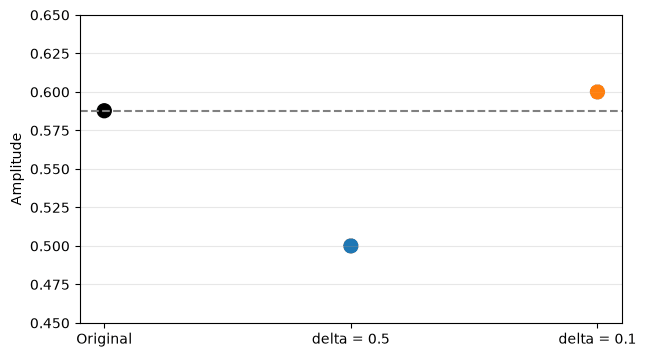

In [6]:
# 第二个采样值，约为 0.5878
value = x[1]

# 对同一个数，采用两种量化间隔
coarse = 0.5 * np.round(value / 0.5)
fine = 0.1 * np.round(value / 0.1)

plt.figure(figsize=(7, 4))

# 三个点：原始值、粗量化结果、细量化结果
plt.scatter(
    [0, 1, 2],
    [value, coarse, fine],
    color=["black", "tab:blue", "tab:orange"],
    s=100
)

# 虚线标出原始值，方便比较偏差
plt.axhline(value, color="gray", linestyle="--")

plt.xticks([0, 1, 2], ["Original", "delta = 0.5", "delta = 0.1"])
plt.ylim(0.45, 0.65)  # 放大纵轴范围
plt.ylabel("Amplitude")
plt.grid(axis="y", alpha=0.3)
plt.show()